In [142]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [143]:
import pandas as pd
import numpy as np
from scipy.stats.mstats import winsorize
import matplotlib.pyplot as plt
import seaborn as sns

NOTE:
(- Chưa xử lý outlier)
- Chưa thử onehot encode cho các biến phân loại
- Thêm các chiến lược chuẩn hóa nếu cần (log transform + standard scaler cho ppi và brand_encoded(lấy giá trị trung bình theo brand) -> so sánh)
....

In [144]:
path = '/content/drive/MyDrive/Python for ML/dataset/cleaned_all_phones.csv'

In [145]:
df = pd.read_csv(path)
df.head(2)

,phone_name,brand,os,inches,resolution,battery,battery_type,ram(GB),announcement_date,weight(g),...,video_1080p,video_4K,video_8K,video_30fps,video_60fps,video_120fps,video_240fps,video_480fps,video_960fps,price(USD)
0,Y6II Compact,Huawei,Android 5.1,5.0,720x1280,2200,Li-Po,2,2016-09-01,140.0,...,False,False,False,True,False,False,False,False,False,120.0
1,K20 plus,LG,Android 7.0,5.3,720x1280,2700,Li-Ion,2,2016-12-01,140.0,...,True,False,False,True,False,False,False,False,False,100.0


#Các biến số

In [146]:
num_cols = ['inches', 'battery', 'ram(GB)', 'weight(g)', 'storage(GB)', 'price(USD)']

Xem lại các thống kê và boxplot của biến số trước xử lý

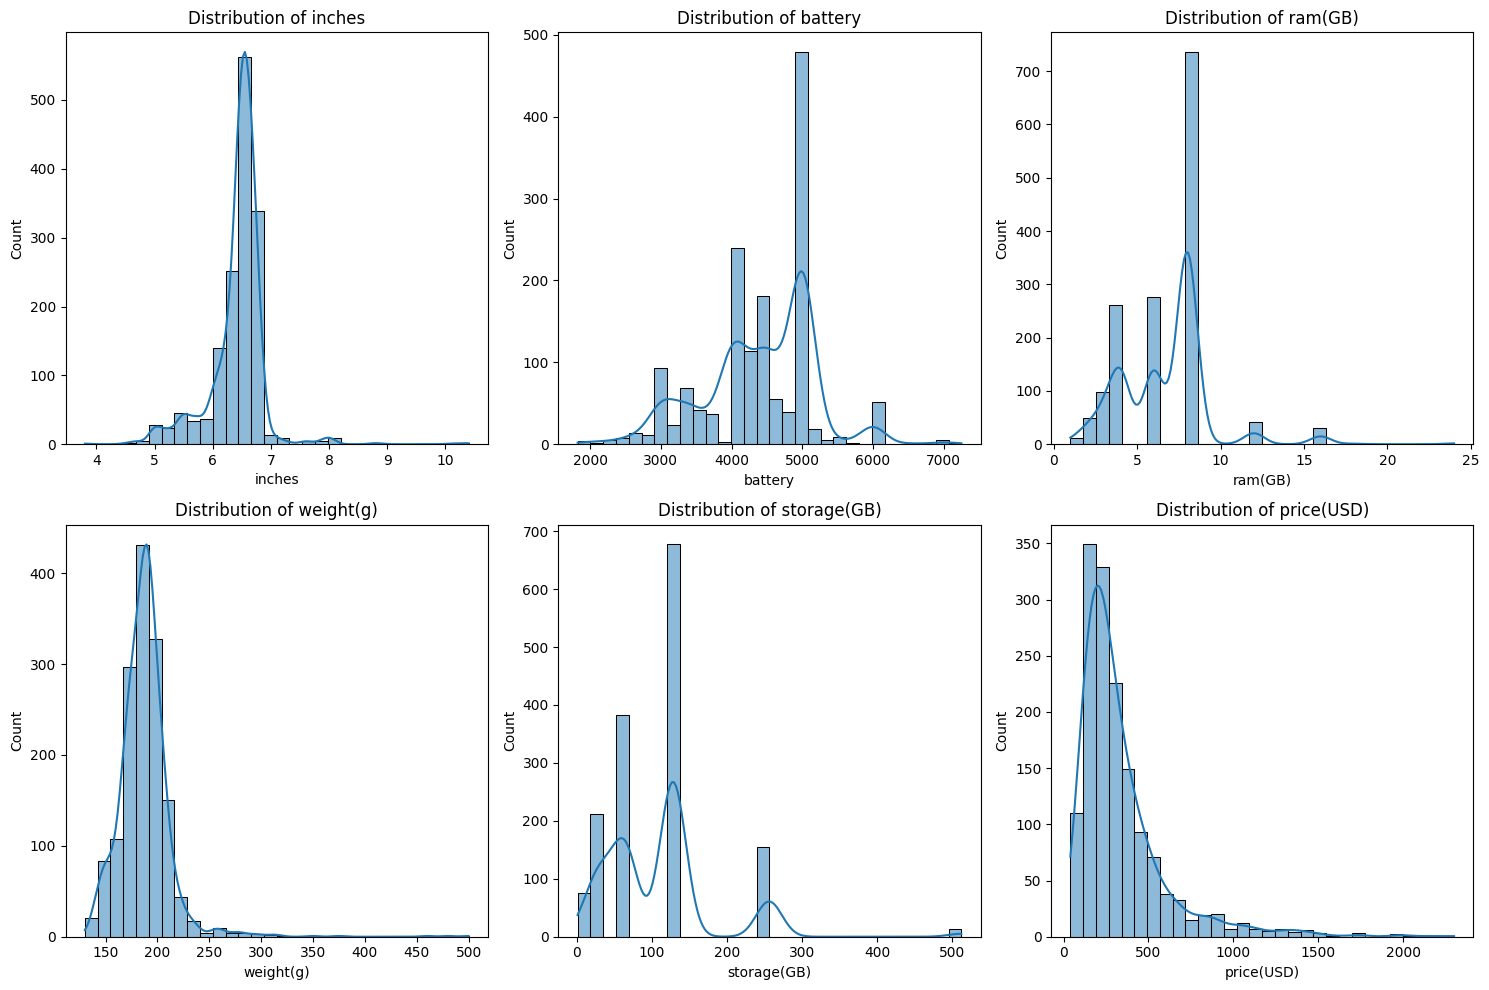

In [147]:
plt.figure(figsize=(15, 10))
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

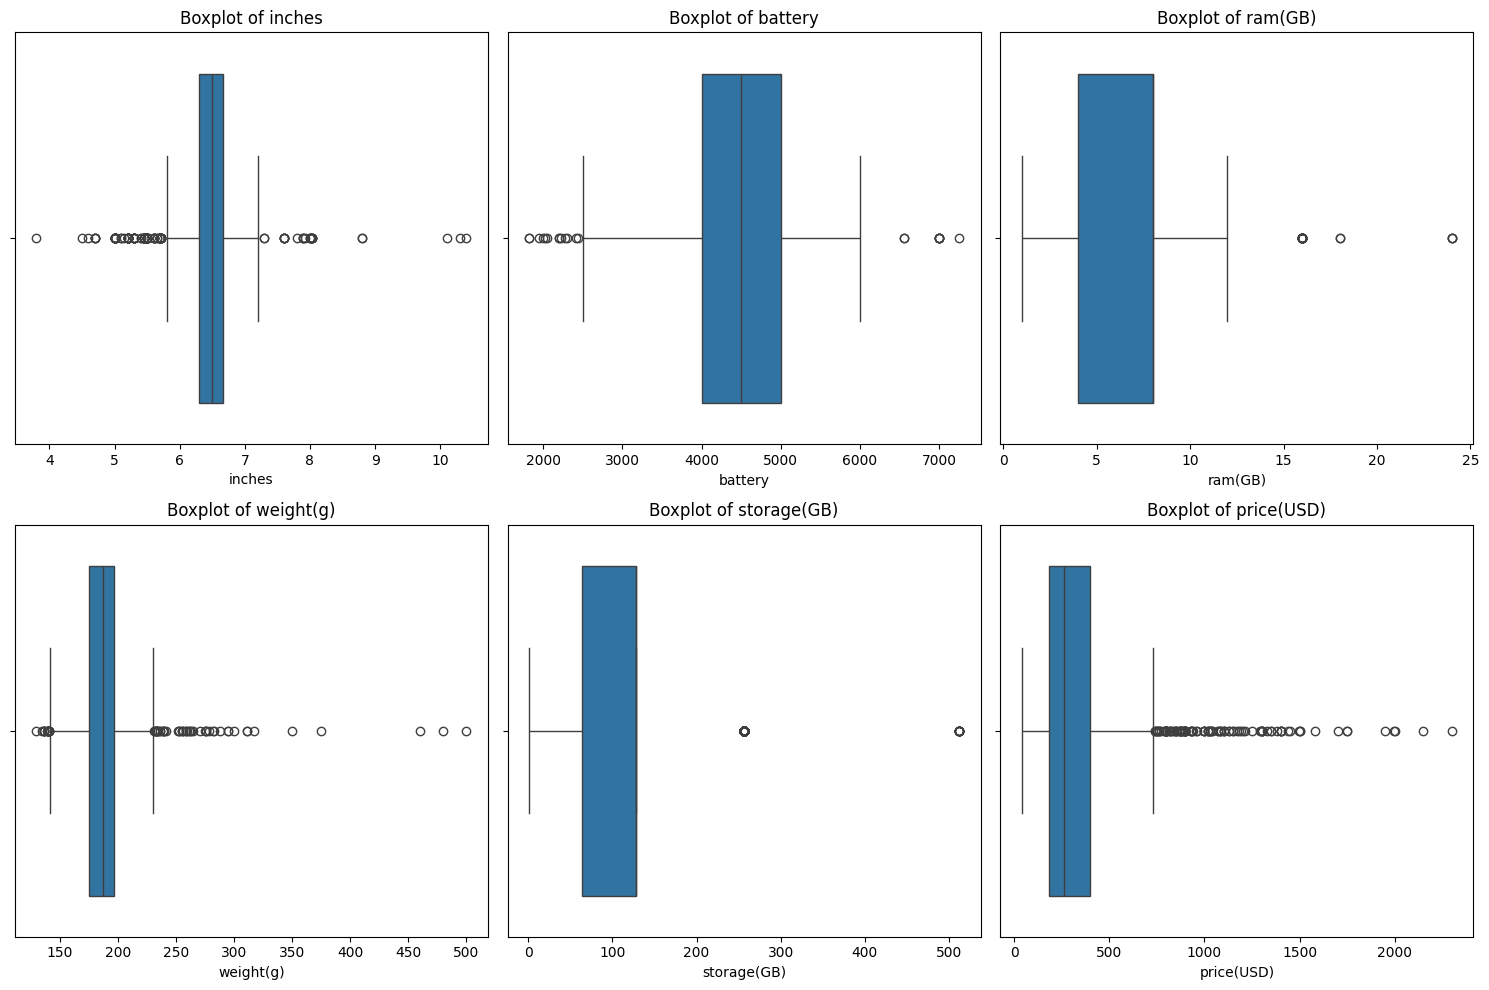

In [148]:
plt.figure(figsize=(15, 10))
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()

#Các biến phân loại

In [149]:
df = df[df['os'] != 'Tizen 3.0']

In [150]:
cate_cols = ['brand', 'os', 'battery_type']

label encode os: theo thế hệ

In [151]:
def categorize_os(os):
    os = str(os).lower()
    if any(v in os for v in ['android 5', 'android 6', 'android 7', 'android 8','ios 11',  'emui 12']):
        return 'old'
    elif any(v in os for v in ['android 9', 'android 10', 'android 11', 'ios 12', 'ios 13', 'ios 14', 'emui 13']):
        return 'mid'
    elif any(v in os for v in ['android 12', 'android 13', 'ios 15', 'ios 16']):
        return 'new'
    else:
        return 'unknown'

df['os_group'] = df['os'].apply(categorize_os)

<ipython-input-151-cb4f4e8645e5>:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['os_group'] = df['os'].apply(categorize_os)


In [152]:
os_group_mapping = {'old': 0, 'mid': 1, 'new': 2, 'unknown': -1}
df['os_group_encoded'] = df['os_group'].map(os_group_mapping)
#df.drop(['os', 'os_group'], axis=1, inplace=True)

<ipython-input-152-8276f925cf24>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['os_group_encoded'] = df['os_group'].map(os_group_mapping)


battery_type: Li-Po-0; Li-Ion-1

In [153]:
battery_mapping = {'Li-Po': 0, 'Li-Ion': 1}
df['battery_type_encoded'] = df['battery_type'].map(battery_mapping)
#df.drop('battery_type', axis=1, inplace=True)

<ipython-input-153-32fb3ec754f2>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['battery_type_encoded'] = df['battery_type'].map(battery_mapping)


brand: encode theo giá trung bình

In [154]:
brand_price_mean = df.groupby('brand')['price(USD)'].mean()
brand_price_mean

,price(USD)
brand,
Apple,680.037273
Google,448.082632
Honor,358.317984
Huawei,403.913650
LG,264.000000
Lenovo,245.116279
OnePlus,421.010723
Oppo,341.332000
Realme,242.407732


In [155]:
df['brand_encoded'] = df['brand'].map(brand_price_mean)
#df.drop('brand', axis=1, inplace=True)

<ipython-input-155-d24baf1f769f>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['brand_encoded'] = df['brand'].map(brand_price_mean)


#Các biến bool

Các chức năng camera nếu có TRUE->1, nếu không FALSE->0

In [156]:
video_cols = [
    'video_720p', 'video_1080p', 'video_4K', 'video_8K',
    'video_30fps', 'video_60fps', 'video_120fps',
    'video_240fps', 'video_480fps', 'video_960fps'
]

# Convert True/False to int (1/0)
df[video_cols] = df[video_cols].astype(int)

<ipython-input-156-b8faaab3deda>:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[video_cols] = df[video_cols].astype(int)


#Khác

resolution

In [157]:
df[['width', 'height']] = df['resolution'].str.lower().str.strip().str.split('x', expand=True).astype(int)
#df.drop(columns=['resolution'], inplace=True)

<ipython-input-157-c6757095a927>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[['width', 'height']] = df['resolution'].str.lower().str.strip().str.split('x', expand=True).astype(int)
<ipython-input-157-c6757095a927>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[['width', 'height']] = df['resolution'].str.lower().str.strip().str.split('x', expand=True).astype(int)


announcement_date -> announcement_year

In [158]:
# Chuyển 'announcement_date' về dạng datetime
df['announcement_date'] = pd.to_datetime(df['announcement_date'], errors='coerce')

# Tạo cột 'announcement_year'
df['announcement_year'] = df['announcement_date'].dt.year

#Xóa 'announcement_date'
#df.drop(columns=['announcement_date'], inplace=True)

<ipython-input-158-848dbc2f8482>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['announcement_date'] = pd.to_datetime(df['announcement_date'], errors='coerce')
<ipython-input-158-848dbc2f8482>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['announcement_year'] = df['announcement_date'].dt.year


total_cam_func: tổng số chức năng camera của thiết bị

In [159]:
#Tạo thêm 1 cột tổng các chức năng camera
total_cam_func = [ i for i in df.columns if 'video' in i]
df['total_cam_func'] = df[total_cam_func].sum(axis=1)

<ipython-input-159-288294576e0f>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['total_cam_func'] = df[total_cam_func].sum(axis=1)


ppi: pixel per inche

In [160]:
df['ppi'] = ((df['width']**2 + df['height']**2)**0.5) / df['inches']

<ipython-input-160-df66ac5a0b08>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['ppi'] = ((df['width']**2 + df['height']**2)**0.5) / df['inches']


Xóa os: Tizen 3.0 (chỉ có duy nhất 1 và đã bị khai tử năm 2022)

In [161]:
df.head(10)

,phone_name,brand,os,inches,resolution,battery,battery_type,ram(GB),announcement_date,weight(g),...,price(USD),os_group,os_group_encoded,battery_type_encoded,brand_encoded,width,height,announcement_year,total_cam_func,ppi
0,Y6II Compact,Huawei,Android 5.1,5.0,720x1280,2200,Li-Po,2,2016-09-01,140.0,...,120.0,old,0,0,403.913650,720,1280,2016,2,293.720956
1,K20 plus,LG,Android 7.0,5.3,720x1280,2700,Li-Ion,2,2016-12-01,140.0,...,100.0,old,0,1,264.000000,720,1280,2016,2,277.095242
2,P8 Lite (2017),Huawei,Android 7.0,5.2,1080x1920,3000,Li-Ion,4,2017-01-01,147.0,...,420.0,old,0,1,403.913650,1080,1920,2017,2,423.635994
3,Redmi Note 4,Xiaomi,Android 6.0,5.5,1080x1920,4100,Li-Po,4,2017-01-01,165.0,...,150.0,old,0,0,306.254129,1080,1920,2017,4,400.528576
4,P10,Huawei,Android 7.0,5.1,1080x1920,3200,Li-Ion,4,2017-02-01,145.0,...,420.0,old,0,1,403.913650,1080,1920,2017,5,431.942582
5,Xperia XA1,Sony,Android 7.0,5.0,720x1280,2300,Li-Ion,3,2017-02-01,143.0,...,140.0,old,0,1,470.782703,720,1280,2017,2,293.720956
6,P10 Lite,Huawei,Android 7.0,5.2,1080x1920,3000,Li-Po,4,2017-02-01,146.0,...,420.0,old,0,0,403.913650,1080,1920,2017,2,423.635994
7,P10 Plus,Huawei,Android 7.0,5.5,1440x2560,3750,Li-Ion,6,2017-02-01,165.0,...,170.0,old,0,1,403.913650,1440,2560,2017,5,534.038102
8,Xperia XA1 Ultra,Sony,Android 7.0,6.0,1080x1920,2700,Li-Ion,4,2017-02-01,188.0,...,250.0,old,0,1,470.782703,1080,1920,2017,2,367.151195
9,X power2,LG,Android 7.0,5.5,720x1280,4500,Li-Ion,2,2017-02-01,164.0,...,170.0,old,0,1,264.000000,720,1280,2017,3,267.019051


#Outlier

In [162]:
count = (df['inches'] >= 9).sum()
print("So thiet bi co man hinh >= 9inches:", count)
count = (df['storage(GB)'] <= 2).sum()
print("So thiet bi co rom <= 2GB:", count)
count = (df['weight(g)'] >= 450).sum()
print("So thiet bi co weight(g) >= 450g:", count)

So thiet bi co man hinh >= 9inches: 3
So thiet bi co rom <= 2GB: 1
So thiet bi co weight(g) >= 450g: 3


In [163]:
# Xóa các dòng thỏa mãn bất kỳ điều kiện nào trong 3 điều kiện
df = df[~(
    (df['inches'] >= 9) |
    (df['storage(GB)'] <= 2) |
    (df['weight(g)'] >= 350)
)]

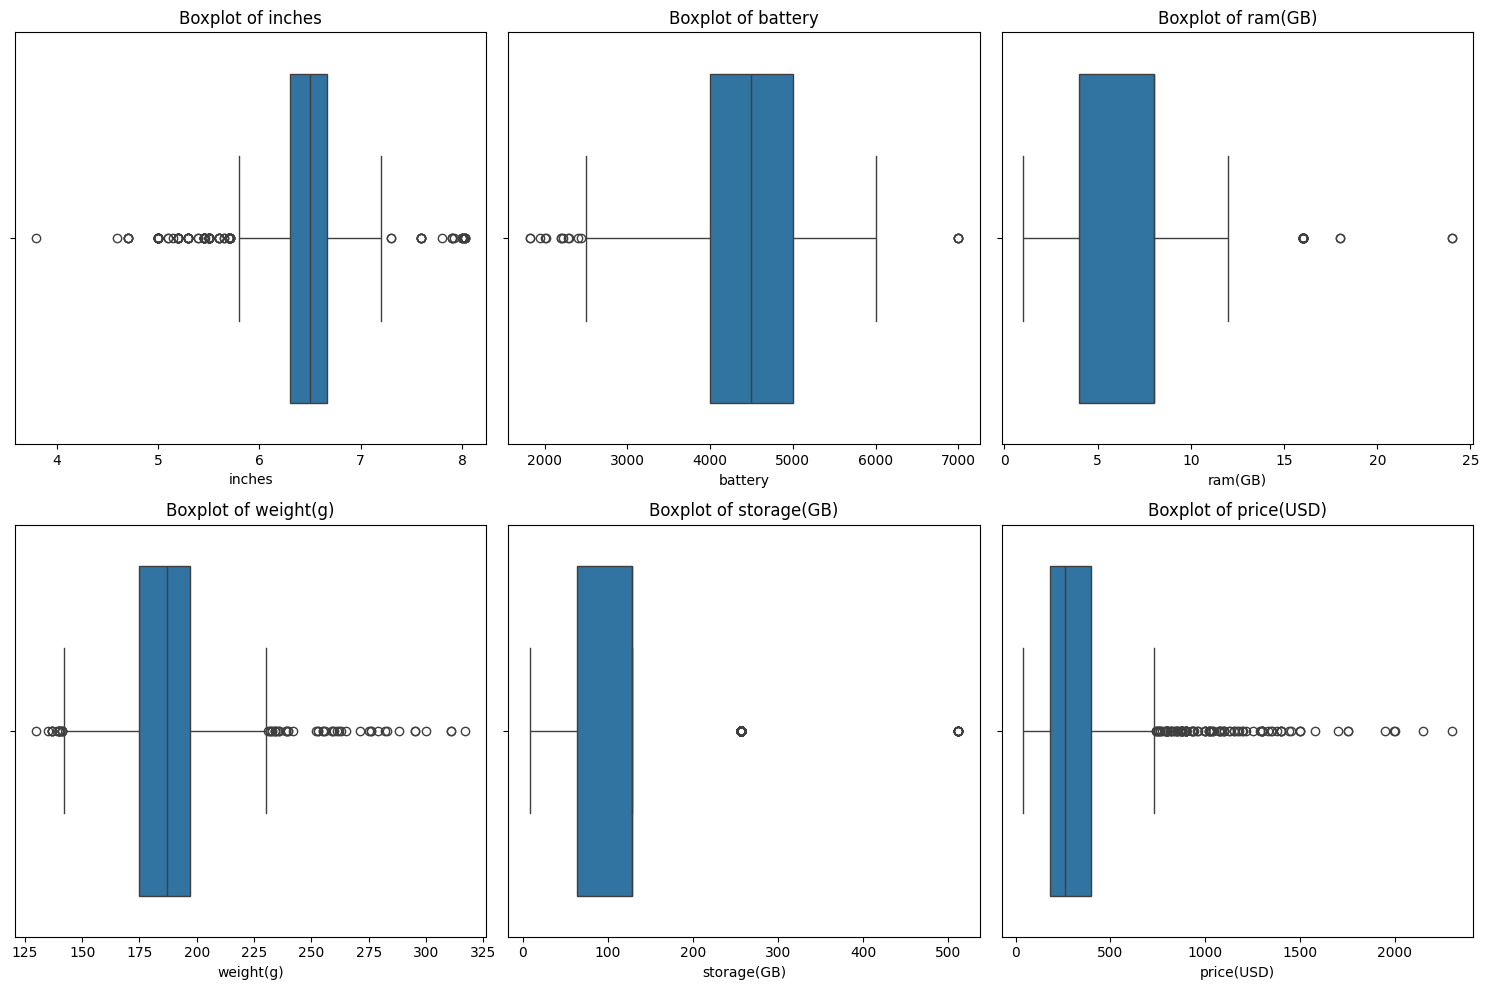

In [164]:
plt.figure(figsize=(15, 10))
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()

In [165]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1505 entries, 0 to 1511
Data columns (total 31 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   phone_name            1505 non-null   object        
 1   brand                 1505 non-null   object        
 2   os                    1505 non-null   object        
 3   inches                1505 non-null   float64       
 4   resolution            1505 non-null   object        
 5   battery               1505 non-null   int64         
 6   battery_type          1505 non-null   object        
 7   ram(GB)               1505 non-null   int64         
 8   announcement_date     1505 non-null   datetime64[ns]
 9   weight(g)             1505 non-null   float64       
 10  storage(GB)           1505 non-null   int64         
 11  video_720p            1505 non-null   int64         
 12  video_1080p           1505 non-null   int64         
 13  video_4K              1

#Chuẩn hóa

In [166]:
num_cols = ['inches', 'battery', 'ram(GB)', 'weight(g)', 'storage(GB)', 'price(USD)', 'ppi', 'brand_encoded']

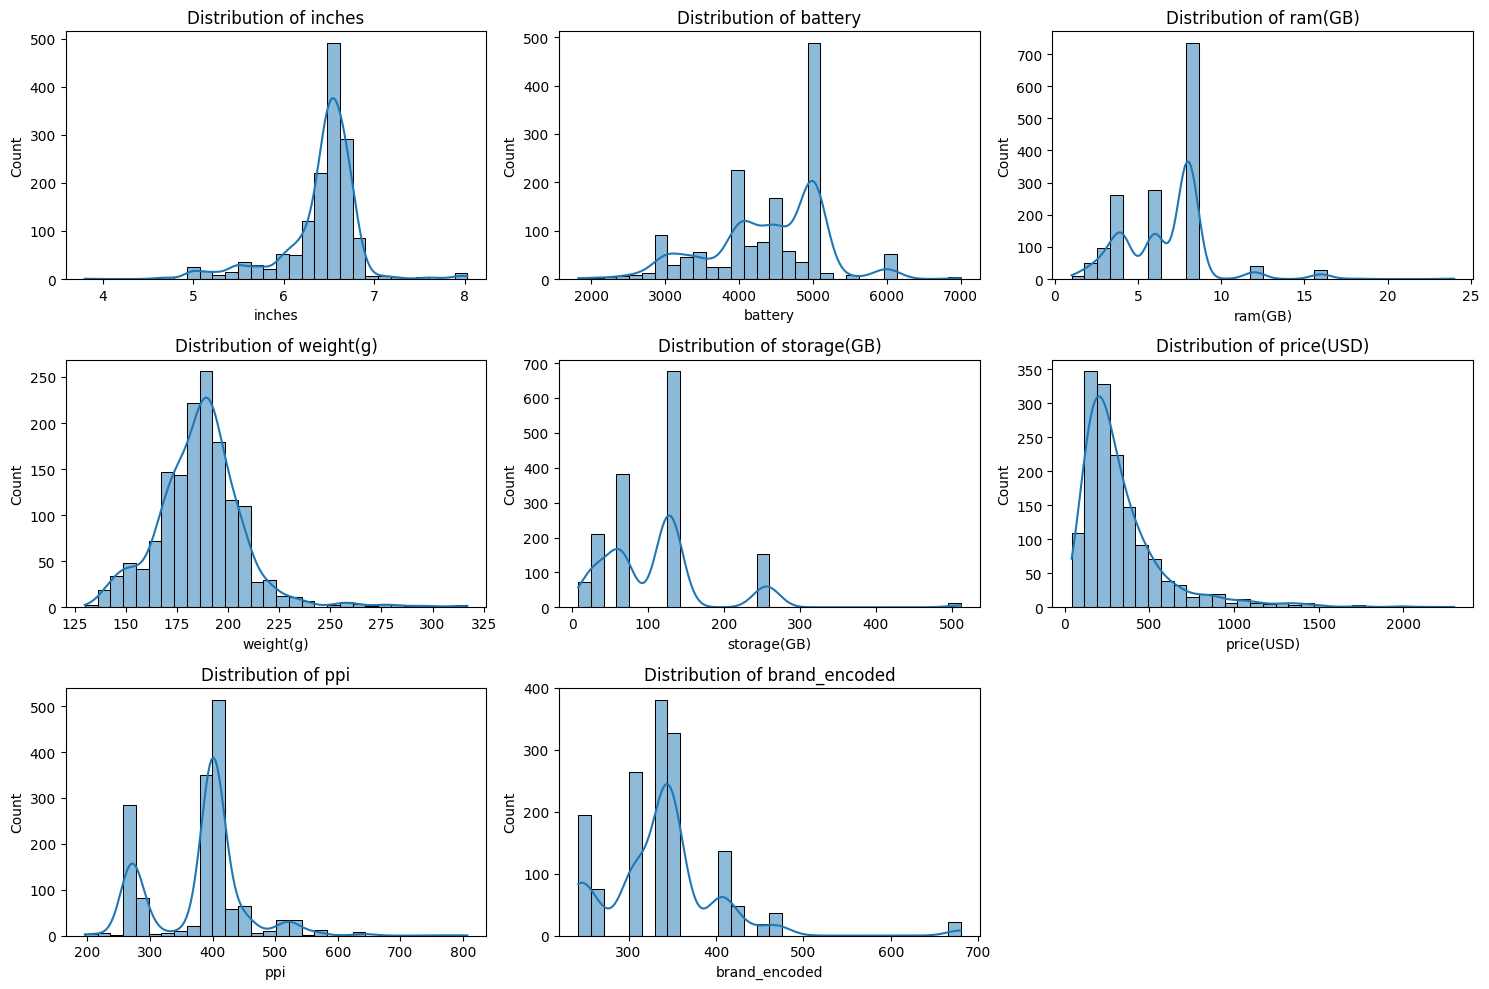

In [167]:
plt.figure(figsize=(15, 10))
for i, col in enumerate(num_cols, 1):
    plt.subplot(3, 3, i)
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

Thêm cột log transform (price(USD)) + log transform + standard scaler cho ppi, ram, storage, brand_encoded

In [168]:
df['ppi_log'] = np.log(df['ppi'])
df['brand_encoded_log'] = np.log(df['brand_encoded'])
df['price(USD)_log'] = np.log(df['price(USD)'])
df['storage(GB)_log'] = np.log(df['storage(GB)'])
df['ram(GB)_log'] = np.log(df['ram(GB)'])

In [169]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

df['ppi_scale'] = scaler.fit_transform(df[['ppi_log']])
df['brand_encoded_scale'] = scaler.fit_transform(df[['brand_encoded_log']])
df['storage(GB)_scale'] = scaler.fit_transform(df[['storage(GB)_log']])
df['ram(GB)_scale'] = scaler.fit_transform(df[['ram(GB)_log']])

In [170]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1505 entries, 0 to 1511
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   phone_name            1505 non-null   object        
 1   brand                 1505 non-null   object        
 2   os                    1505 non-null   object        
 3   inches                1505 non-null   float64       
 4   resolution            1505 non-null   object        
 5   battery               1505 non-null   int64         
 6   battery_type          1505 non-null   object        
 7   ram(GB)               1505 non-null   int64         
 8   announcement_date     1505 non-null   datetime64[ns]
 9   weight(g)             1505 non-null   float64       
 10  storage(GB)           1505 non-null   int64         
 11  video_720p            1505 non-null   int64         
 12  video_1080p           1505 non-null   int64         
 13  video_4K              1

#One hot encode cho các biến phân loại (để so sánh)

In [177]:
df_encoded = pd.get_dummies(df, columns=['brand', 'os', 'battery_type'])

In [178]:
df_encoded.drop(columns=['battery_type_encoded', 'ppi_log', 'storage(GB)_log', 'ram(GB)_log', 'phone_name', 'os_group', 'os_group_encoded', 'resolution', 'ram(GB)', 'storage(GB)', 'announcement_date', 'ppi', 'brand_encoded', 'brand_encoded_log', 'brand_encoded_scale'], inplace=True)

In [179]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1505 entries, 0 to 1511
Data columns (total 70 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   inches                     1505 non-null   float64
 1   battery                    1505 non-null   int64  
 2   weight(g)                  1505 non-null   float64
 3   video_720p                 1505 non-null   int64  
 4   video_1080p                1505 non-null   int64  
 5   video_4K                   1505 non-null   int64  
 6   video_8K                   1505 non-null   int64  
 7   video_30fps                1505 non-null   int64  
 8   video_60fps                1505 non-null   int64  
 9   video_120fps               1505 non-null   int64  
 10  video_240fps               1505 non-null   int64  
 11  video_480fps               1505 non-null   int64  
 12  video_960fps               1505 non-null   int64  
 13  price(USD)                 1505 non-null   float64
 1

In [180]:
df.drop(columns=['ppi_log', 'brand_encoded_log', 'storage(GB)_log', 'ram(GB)_log', 'phone_name', 'brand', 'os', 'os_group', 'resolution', 'battery_type', 'ram(GB)', 'storage(GB)', 'announcement_date', 'ppi', 'brand_encoded'], inplace=True)

In [181]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1505 entries, 0 to 1511
Data columns (total 25 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   inches                1505 non-null   float64
 1   battery               1505 non-null   int64  
 2   weight(g)             1505 non-null   float64
 3   video_720p            1505 non-null   int64  
 4   video_1080p           1505 non-null   int64  
 5   video_4K              1505 non-null   int64  
 6   video_8K              1505 non-null   int64  
 7   video_30fps           1505 non-null   int64  
 8   video_60fps           1505 non-null   int64  
 9   video_120fps          1505 non-null   int64  
 10  video_240fps          1505 non-null   int64  
 11  video_480fps          1505 non-null   int64  
 12  video_960fps          1505 non-null   int64  
 13  price(USD)            1505 non-null   float64
 14  os_group_encoded      1505 non-null   int64  
 15  battery_type_encoded  1505

In [182]:
#Luu df lai
path_label_encode = '/content/drive/MyDrive/Python for ML/dataset/cleaned_all_phones_label_encode.csv'
path_one_hot = '/content/drive/MyDrive/Python for ML/dataset/cleaned_all_phones_one_hot.csv'
df.to_csv(path_label_encode, index=False)
df_encoded.to_csv(path_one_hot, index=False)